# Regresyon ile Eksik İlaç Sayısı Tamamlama

Bu çalışmada **Diabetes 130-US Hospitals (1999–2008)** veri setindeki ilaç sayısı
bilgisini diğer hasta ve yatış özelliklerinden yararlanarak tahmin ettim.
Hedef değişken olarak `num_medications` sütununu, model olarak **Linear Regression** kullandım.

Veriyi incelediğimde bu sütunda doğal eksik değer bulunmadığını gördüm. Eksik veri
tamamlamayı uygulamak ve tahminlerimi gerçek değerlerle karşılaştırmak için ilaç
sayılarının **%20'sini rastgele gizledim**. Gizlediğim gerçekleri eğitimde kullanmadım.

Çalışmamı veri inceleme, hedef ve giriş seçimi, ön işleme, eğitim, değerlendirme ve
boşlukları doldurma adımlarıyla hazırladım. `readmitted` sütununu model girişlerine eklemedim.

## 1. Kullandığım kütüphaneler

Veri işlemleri için NumPy ve pandas, görselleştirme için Matplotlib,
ön işleme ve regresyon için scikit-learn kullandım. Aşağıdaki hücrede gerekli
kütüphaneleri kontrol ettim; eksik veya eski olanlar varsa notebook içinde kurulum yaptım.

In [1]:
import importlib.util
from importlib.metadata import version

gereksinimler = {
    'numpy': ('numpy', (1, 26)),
    'pandas': ('pandas', (2, 0)),
    'matplotlib': ('matplotlib', (3, 8)),
    'scikit-learn': ('sklearn', (1, 7)),
}
kurulacaklar = []
for paket, (modul, en_az_surumu) in gereksinimler.items():
    if importlib.util.find_spec(modul) is None:
        kurulacaklar.append(paket)
    else:
        mevcut = tuple(int(x) for x in version(paket).split('.')[:2])
        if mevcut < en_az_surumu:
            kurulacaklar.append(paket)
if kurulacaklar:
    komut = '-q --upgrade ' + ' '.join(kurulacaklar)
    get_ipython().run_line_magic('pip', 'install ' + komut)

import hashlib
import io
import warnings
import zipfile
from urllib.request import urlopen

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
from IPython.display import display, Markdown
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import GroupShuffleSplit
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

get_ipython().run_line_magic('matplotlib', 'inline')
pd.set_option('display.max_columns', 12)
print('NumPy:', np.__version__)
print('pandas:', pd.__version__)
print('scikit-learn:', sklearn.__version__)

NumPy: 2.3.5
pandas: 3.0.1
scikit-learn: 1.9.1


## 2. Veri setini okuma

Veriyi UCI'nin resmi bağlantısından doğrudan indirdim. ZIP içindeki CSV'yi bellekte
okudum; böylece notebook'u çalıştırmak için yanında ayrı bir veri dosyasına ihtiyaç bırakmadım.

`keep_default_na=False` kullandım. Bunun nedeni, `A1Cresult` ve `max_glu_serum`
sütunlarındaki `None` ifadesinin testin yapılmadığını belirten bir kategori olması.
Kimlik ve tanı kodlarının anlamını korumak için başlangıçta bütün sütunları metin
olarak okudum; sayısal girişleri daha sonra dönüştürdüm.

In [2]:
TARGET = 'num_medications'
MASK_RATE = 0.20
MASK_SEED = 42
SPLIT_SEED = 2026
SOURCE_URL = 'https://archive.ics.uci.edu/static/public/296/diabetes%2B130-us%2Bhospitals%2Bfor%2Byears%2B1999-2008.zip'

with urlopen(SOURCE_URL, timeout=60) as response:
    zip_bytes = response.read()
with zipfile.ZipFile(io.BytesIO(zip_bytes)) as archive:
    source_bytes = archive.read('diabetic_data.csv')

raw = pd.read_csv(io.BytesIO(source_bytes), dtype=str, keep_default_na=False)
source_sha256 = hashlib.sha256(source_bytes).hexdigest()
assert raw.shape == (101766, 50), f'Beklenmeyen veri boyutu: {raw.shape}'
assert raw['encounter_id'].is_unique
original_y = pd.to_numeric(raw[TARGET], errors='raise')
assert (original_y >= 1).all()
assert np.equal(original_y, np.floor(original_y)).all()
original_y = original_y.astype(int)

print(f'Kayıt sayısı: {len(raw):,}')
print(f'Sütun sayısı: {raw.shape[1]}')
print(f'Farklı hasta sayısı: {raw.patient_nbr.nunique():,}')
print('Kaynak CSV özeti (SHA-256):', source_sha256)
display(raw.head())

Kayıt sayısı: 101,766
Sütun sayısı: 50
Farklı hasta sayısı: 71,518
Kaynak CSV özeti (SHA-256): 0689e7ec031237dc63031b938805c48377748761a3b26acab621567afa24df97


,encounter_id,patient_nbr,race,gender,age,weight,...,glimepiride-pioglitazone,metformin-rosiglitazone,metformin-pioglitazone,change,diabetesMed,readmitted
0,2278392,8222157,Caucasian,Female,[0-10),?,...,No,No,No,No,No,NO
1,149190,55629189,Caucasian,Female,[10-20),?,...,No,No,No,Ch,Yes,>30
2,64410,86047875,AfricanAmerican,Female,[20-30),?,...,No,No,No,No,Yes,NO
3,500364,82442376,Caucasian,Male,[30-40),?,...,No,No,No,Ch,Yes,NO
4,16680,42519267,Caucasian,Male,[40-50),?,...,No,No,No,Ch,Yes,NO


## 3. Eksik değerleri inceleme

Sütunlardaki `?` işaretlerini ve boş hücreleri saydım. `None` kategorisini ayrıca
gösterdim. Sayım sütunlarındaki sıfırları ve ilaç sütunlarındaki `No` değerlerini
eksik kabul etmedim.

Doğal eksikleri `race`, `weight`, `payer_code`, `medical_specialty` ve tanı kodu
sütunlarında gördüm. `weight` değerleri ağırlık aralıkları, `diag_1/2/3` değerleri ise
tanı kodları olduğu için bunları sürekli sayısal ölçüm olarak ele almadım.

In [3]:
explicit_missing = raw.isin(['?', '']).sum()
missing_table = pd.DataFrame({
    'sutun': raw.columns,
    'dogal_eksik': explicit_missing.to_numpy(),
    'oran_yuzde': 100 * explicit_missing.to_numpy() / len(raw),
    'None_kategorisi': raw.eq('None').sum().to_numpy(),
})
display(missing_table.loc[(missing_table.dogal_eksik > 0) | (missing_table.None_kategorisi > 0)].reset_index(drop=True))
print('Hedefte doğal eksik:', int(explicit_missing[TARGET]))
assert explicit_missing[TARGET] == 0

,sutun,dogal_eksik,oran_yuzde,None_kategorisi
0,race,2273,2.233555,0
1,weight,98569,96.858479,0
2,payer_code,40256,39.557416,0
3,medical_specialty,49949,49.082208,0
4,diag_1,21,0.020636,0
5,diag_2,358,0.351787,0
6,diag_3,1423,1.398306,0
7,max_glu_serum,0,0.000000,96420
8,A1Cresult,0,0.000000,84748


Hedefte doğal eksik: 0


## 4. Hedef değişkenimi belirleme

Hedefim `num_medications`, yani yatış sırasında verilen **farklı jenerik ilaç sayısı**.
Bu değişken doz veya toplam hap sayısını göstermiyor. Tamsayı bir sayım değişkeni
olduğu için regresyonun ondalıklı tahminlerini doldurma aşamasında tamsayıya dönüştürdüm.

Önce hedefin dağılımını ve değer aralığını inceledim.

,İlaç sayısı
count,101766.000000
mean,16.021844
std,8.127566
min,1.000000
25%,10.000000
50%,15.000000
75%,20.000000
max,81.000000


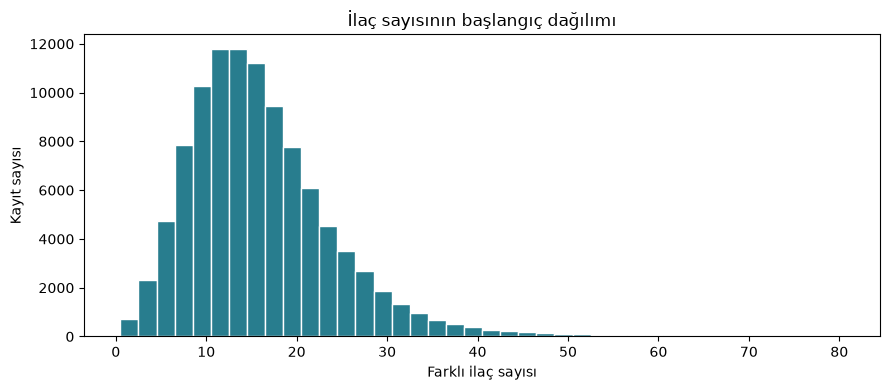

In [4]:
display(original_y.describe().rename('İlaç sayısı').to_frame())
fig, ax = plt.subplots(figsize=(9, 4))
ax.hist(original_y, bins=np.arange(0.5, 82.5, 2), color='#287d8e', edgecolor='white')
ax.set(title='İlaç sayısının başlangıç dağılımı', xlabel='Farklı ilaç sayısı', ylabel='Kayıt sayısı')
fig.tight_layout()
plt.show()
plt.close(fig)

## 5. Yapay eksiklik oluşturma

Hedefin %20'sini rastgele seçip yalnızca bu hücreleri boşalttım. Satırları silmedim.
101.766 × 0,20 işlemi tam sayı vermediği için **20.353 hücre** seçtim.

Rastgele seçimde sabit tohum kullandım. Seçimi ilaç sayısına bakmadan yaptım.
Gerçek değerleri ayrı tuttum; modelime yalnızca kalan bilinen hedefleri verdim.

In [5]:
rng = np.random.default_rng(MASK_SEED)
masked_rows = np.sort(rng.choice(len(raw), size=round(len(raw) * MASK_RATE), replace=False))
is_masked = np.zeros(len(raw), dtype=bool)
is_masked[masked_rows] = True
masked = raw.copy(deep=True)
masked.loc[is_masked, TARGET] = ''
y_visible = pd.to_numeric(masked[TARGET], errors='coerce')
assert y_visible.isna().sum() == len(masked_rows)
known_rows = np.flatnonzero(~is_masked)
masked_truth = original_y.iloc[masked_rows].copy()
print(f'Yapay eksik: {len(masked_rows):,} (%{100 * is_masked.mean():.4f})')
print(f'Bilinen hedef: {len(known_rows):,}')

Yapay eksik: 20,353 (%19.9998)
Bilinen hedef: 81,413


## 6. Giriş değişkenlerimi seçme ve veriyi ayırma

Model girişlerinden `num_medications`, `readmitted`, `encounter_id`, `patient_nbr`
ve `weight` sütunlarını çıkardım. Kimlikleri açıklayıcı özellik olarak kullanmadım.
`weight` sütununu eksik oranı yaklaşık %96,86 olduğu için dışarıda bıraktım.
Böylece **7 sayısal ve 38 kategorik olmak üzere 45 giriş sütunu** kullandım.

Aynı hastanın birden fazla yatışı olduğunu gördüğüm için hedefi bilinen kayıtları
hasta bazında eğitim ve teste ayırdım. `patient_nbr` sütununu yalnızca bu gruplamayı
yapmak için kullandım. Aynı hastanın kayıtlarının hem eğitimde hem testte bulunmasını
önledim. Teste hasta gruplarının %20'sini ayırdım; bu nedenle kayıt oranı yaklaşık %20 oldu.

Bu test ayrımını yapay boşluklardan ayrı tuttum. Önce bilinen hedeflerle bağımsız
değerlendirme yaptım; ardından boşlukları doldurmak için bilinen hedeflerin tamamından yararlandım.

In [6]:
EXCLUDED = [TARGET, 'readmitted', 'encounter_id', 'patient_nbr', 'weight']
NUMERIC = [
    'time_in_hospital', 'num_lab_procedures', 'num_procedures',
    'number_outpatient', 'number_emergency', 'number_inpatient', 'number_diagnoses',
]
X = masked.drop(columns=EXCLUDED).replace({'?': np.nan, '': np.nan})
CATEGORICAL = [c for c in X.columns if c not in NUMERIC]
for col in NUMERIC:
    X[col] = pd.to_numeric(X[col], errors='raise')
assert X.shape[1] == 45 and len(CATEGORICAL) == 38
assert set(EXCLUDED).isdisjoint(X.columns)
splitter = GroupShuffleSplit(n_splits=1, test_size=0.20, random_state=SPLIT_SEED)
train_rel, test_rel = next(splitter.split(
    X.iloc[known_rows], y_visible.iloc[known_rows], groups=raw.patient_nbr.iloc[known_rows]
))
train_rows, test_rows = known_rows[train_rel], known_rows[test_rel]
train_patients = set(raw.patient_nbr.iloc[train_rows])
test_patients = set(raw.patient_nbr.iloc[test_rows])
assert train_patients.isdisjoint(test_patients)
assert set(train_rows).isdisjoint(masked_rows) and set(test_rows).isdisjoint(masked_rows)
print('Giriş sayısı:', X.shape[1], '| Sayısal:', len(NUMERIC), '| Kategorik:', len(CATEGORICAL))
print('Eğitim kaydı:', len(train_rows), '| Bağımsız test kaydı:', len(test_rows))
print('Eğitim-test ortak hasta:', len(train_patients & test_patients))
display(pd.DataFrame({'Sütun': X.columns, 'Tür': ['Sayısal' if c in NUMERIC else 'Kategorik' for c in X.columns]}))

Giriş sayısı: 45 | Sayısal: 7 | Kategorik: 38
Eğitim kaydı: 65089 | Bağımsız test kaydı: 16324
Eğitim-test ortak hasta: 0


,Sütun,Tür
0,race,Kategorik
1,gender,Kategorik
2,age,Kategorik
3,admission_type_id,Kategorik
4,discharge_disposition_id,Kategorik
5,admission_source_id,Kategorik
6,time_in_hospital,Sayısal
7,payer_code,Kategorik
8,medical_specialty,Kategorik
9,num_lab_procedures,Sayısal


## 7. Ön işleme ve regresyon modelimi kurma

Sayısal girişlere medyanla doldurma ve standardizasyon uyguladım. Kategorik
girişlerdeki eksikleri `Bilinmiyor` kategorisiyle doldurup one-hot kodlama kullandım.
Örneğin kabul türü kodlarını sayısal büyüklük gibi yorumlamadım. Yaş aralıklarını,
tanı kodlarını ve ilaç durumlarını da kategorik olarak kodladım.

Bütün işlemleri `Pipeline` içinde tanımladım. Böylece doldurma, ölçeklendirme ve
kodlama eğitim verisinden öğrenildi; test verisi bu öğrenime katılmadı. İlk kategoriyi
referans olarak çıkardım. Eğitimde görülmeyen kategorileri tüm sıfırlardan oluşan
gösterimle ele aldım; bu kategoriler için ayrı bir etki öğrenilemediğini dikkate aldım.

Kullandığım doğrusal model:

$$
\hat{y} = b_0 + b_1x_1 + \cdots + b_px_p
$$

Model, gerçek ve tahmin edilen ilaç sayıları arasındaki karesel hatalar toplamını
en aza indirecek katsayıları öğrendi. Bu çalışmada **Linear Regression** kullandım;
Ridge veya Lasso cezası eklemedim.

In [7]:
def tahmin_al(model, girdiler):
    # Eğitimde görmediğim kategorilerin sayısını açıkça raporladım.
    encoder = model.named_steps['on_isleme'].named_transformers_['kategorik'].named_steps['kodla']
    yeni_kategoriler = {}
    for sutun, bilinenler in zip(CATEGORICAL, encoder.categories_):
        degerler = girdiler[sutun].fillna('Bilinmiyor')
        sayi = int((~degerler.isin(bilinenler)).sum())
        if sayi:
            yeni_kategoriler[sutun] = sayi
    if yeni_kategoriler:
        print('Eğitimde görülmeyen kategorilere ait hücreler:', yeni_kategoriler)
    # Bu beklenen durumu yukarıda gösterdim; aynı uyarının tekrarını engelledim.
    with warnings.catch_warnings():
        warnings.filterwarnings('ignore', message='Found unknown categories.*', category=UserWarning)
        return model.predict(girdiler)

numeric_pipeline = Pipeline([
    ('doldur', SimpleImputer(strategy='median')),
    ('olcekle', StandardScaler()),
])
category_pipeline = Pipeline([
    ('doldur', SimpleImputer(strategy='constant', fill_value='Bilinmiyor')),
    ('kodla', OneHotEncoder(handle_unknown='ignore', drop='first', sparse_output=True)),
])
preprocessor = ColumnTransformer([
    ('sayisal', numeric_pipeline, NUMERIC),
    ('kategorik', category_pipeline, CATEGORICAL),
], sparse_threshold=1.0)
evaluation_model = Pipeline([
    ('on_isleme', preprocessor),
    ('regresyon', LinearRegression(tol=1e-6)),
])
evaluation_model.fit(X.iloc[train_rows], y_visible.iloc[train_rows])
test_prediction = tahmin_al(evaluation_model, X.iloc[test_rows])
train_prediction = evaluation_model.predict(X.iloc[train_rows])
print('Model eğitildi. Kodlama sonrası giriş sayısı:',
      len(evaluation_model.named_steps['on_isleme'].get_feature_names_out()))

Eğitimde görülmeyen kategorilere ait hücreler: {'medical_specialty': 1, 'diag_1': 25, 'diag_2': 34, 'diag_3': 32, 'troglitazone': 3, 'tolazamide': 1}


Model eğitildi. Kodlama sonrası giriş sayısı: 2316


## 8. Modelimin başarısını ölçme

Performansı eğitimde bulunmayan hastaların test kayıtları üzerinde ölçtüm:

- **MAE:** Tahminlerimin gerçeklerden ortalama kaç ilaç uzakta olduğunu gösteriyor.
- **RMSE:** Büyük hataları daha fazla cezalandırıyor.
- **R²:** Modelin hedefteki değişkenliği ortalamaya göre ne kadar açıkladığını gösteriyor; başarı yüzdesi değil.

Eğitim ve test hatalarını birlikte inceledim. Ayrıca her hastaya eğitim ortalamasını
vermekle elde edilen hatayı basit bir referans olarak hesapladım. Ham ve tamsayıya
çevrilmiş tahminleri ayrı değerlendirdim. Sonuçlara göre farklı bir model seçmedim.

In [8]:
def integer_prediction(values):
    # Tahminleri en yakın tamsayıya yuvarladım ve en az 1 olacak şekilde sınırlandırdım.
    return np.maximum(1, np.floor(np.asarray(values) + 0.5)).astype(int)


def scores(actual, predicted):
    return {
        'MAE': float(mean_absolute_error(actual, predicted)),
        'RMSE': float(np.sqrt(mean_squared_error(actual, predicted))),
        'R2': float(r2_score(actual, predicted)),
    }


test_integer = integer_prediction(test_prediction)
test_y = y_visible.iloc[test_rows].to_numpy()
mean_train = float(y_visible.iloc[train_rows].mean())
evaluation = pd.DataFrame([
    {'degerlendirme': 'Egitim - ham', **scores(y_visible.iloc[train_rows], train_prediction)},
    {'degerlendirme': 'Bagimsiz test - ham', **scores(test_y, test_prediction)},
    {'degerlendirme': 'Bagimsiz test - tamsayi', **scores(test_y, test_integer)},
    {'degerlendirme': 'Bagimsiz test - egitim ortalamasi', **scores(test_y, np.full(len(test_rows), mean_train))},
])
display(evaluation.round(4))

,degerlendirme,MAE,RMSE,R2
0,Egitim - ham,4.1282,5.4684,0.5487
1,Bagimsiz test - ham,4.2260,5.5511,0.5212
2,Bagimsiz test - tamsayi,4.2153,5.5565,0.5203
3,Bagimsiz test - egitim ortalamasi,6.0958,8.0250,-0.0006


## 9. Eksik ilaç sayılarını tahmin etme ve doldurma

Bağımsız test değerlendirmesini bitirdikten sonra aynı yöntemi ilaç sayısı bilinen
**81.413 kaydın tamamıyla** yeniden eğittim. Gizlenen gerçek ilaç sayılarını eğitime
dahil etmedim. Bu modelle 20.353 yapay boşluk için tahmin ürettim.

İlaç sayısı tamsayı olduğu için tahminleri en yakın tamsayıya yuvarladım; tam yarım
değerleri yukarı yuvarlayıp alt sınırı 1 yaptım. Veri seti ilaç uygulanmış yatışlardan
oluştuğu için bu alt sınırı kullandım. Üst sınır uygulamadım ve ham tahminleri ayrıca korudum.

Son olarak tahminleri gizlediğim gerçeklerle karşılaştırdım. Rastgele satır
gizlediğim için bu aşamada aynı hastanın farklı yatışları hem bilinen hem gizlenen
kayıtlar arasında bulunabiliyor. Bu kontrolü, önceki bağımsız hasta testinin yerine koymadım.

In [9]:
final_model = clone(evaluation_model)
final_model.fit(X.iloc[known_rows], y_visible.iloc[known_rows])
missing_prediction = tahmin_al(final_model, X.iloc[masked_rows])
missing_integer = integer_prediction(missing_prediction)
assert np.isfinite(missing_prediction).all()
filled = masked.copy(deep=True)
filled.loc[is_masked, TARGET] = missing_integer.astype(str)
simulation = pd.DataFrame([
    {'degerlendirme': 'Yapay eksikler - ham', **scores(masked_truth, missing_prediction)},
    {'degerlendirme': 'Yapay eksikler - tamsayi', **scores(masked_truth, missing_integer)},
    {'degerlendirme': 'Yapay eksikler - bilinen hedef ortalamasi',
     **scores(masked_truth, np.full(len(masked_rows), y_visible.iloc[known_rows].mean()))},
])
display(simulation.round(4))
print(f'Doldurulan hücre: {len(masked_rows):,}; kalan hedef eksikliği:', filled[TARGET].isin(['?', '']).sum())

Eğitimde görülmeyen kategorilere ait hücreler: {'diag_1': 22, 'diag_2': 40, 'diag_3': 22, 'acetohexamide': 1}


,degerlendirme,MAE,RMSE,R2
0,Yapay eksikler - ham,4.2719,5.6600,0.5201
1,Yapay eksikler - tamsayi,4.2628,5.6644,0.5193
2,Yapay eksikler - bilinen hedef ortalamasi,6.1223,8.1706,-0.0001


Doldurulan hücre: 20,353; kalan hedef eksikliği: 0


## 10. Doldurduğum hücreleri kontrol etme

Yalnızca seçtiğim hedef hücrelerini doldurduğumu kontrol ettim. Başlangıçta bilinen
ilaç sayılarının, diğer 49 sütunun, satır ve sütun sırasının korunduğunu doğruladım.
Diğer sütunlardaki doğal eksikleri sonuç veri setinde değiştirmedim; bunları yalnızca
modelin ön işleme aşamasında ele aldım.

Aşağıda ilk 10 yapay boşluk için gerçek değerleri, ham tahminleri ve doldurduğum
tamsayı değerleri birlikte gösterdim. Bu tabloyu eğitim girdilerine eklemedim.

In [10]:
other_columns = [c for c in raw.columns if c != TARGET]
pd.testing.assert_frame_equal(filled[other_columns], raw[other_columns])
pd.testing.assert_series_equal(filled.loc[~is_masked, TARGET], raw.loc[~is_masked, TARGET])
assert filled.shape == raw.shape
assert list(filled.columns) == list(raw.columns)
assert filled[TARGET].isin(['?', '']).sum() == 0
assert np.isfinite(missing_prediction).all()
assert np.array_equal(pd.to_numeric(filled.loc[is_masked, TARGET]), missing_integer)
assert (pd.to_numeric(filled[TARGET]) >= 1).all()

comparison = pd.DataFrame({
    'Satır indeksi': masked_rows,
    'Gerçek ilaç sayısı': masked_truth.to_numpy(),
    'Ham tahmin': missing_prediction,
    'Doldurduğum ilaç sayısı': missing_integer,
    'Mutlak hata': np.abs(masked_truth.to_numpy() - missing_integer),
})
display(comparison.head(10).round(4))
display(pd.DataFrame({
    'Kontrol': ['Doldurduğum hücre sayısı', 'Hedefte kalan eksik', 'Eğitim-test ortak hasta'],
    'Sonuç': [len(masked_rows), int(filled[TARGET].isin(['?', '']).sum()), len(train_patients & test_patients)],
}))
print('Bilinen ilaç sayılarını ve hedef dışındaki bütün hücreleri korudum.')

,Satır indeksi,Gerçek ilaç sayısı,Ham tahmin,Doldurduğum ilaç sayısı,Mutlak hata
0,0,1,2.5232,3,2
1,26,18,18.6383,19,1
2,28,20,22.8114,23,3
3,32,16,13.0004,13,3
4,37,12,14.6602,15,3
5,38,22,17.4677,17,5
6,39,15,15.0598,15,0
7,46,16,23.8896,24,8
8,51,13,20.0783,20,7
9,55,14,23.1513,23,9


,Kontrol,Sonuç
0,Doldurduğum hücre sayısı,20353
1,Hedefte kalan eksik,0
2,Eğitim-test ortak hasta,0


Bilinen ilaç sayılarını ve hedef dışındaki bütün hücreleri korudum.


## 11. Sonuçları görselleştirme

Önce bilinen ve gizlediğim gerçek ilaç sayılarının dağılımlarını karşılaştırdım.
Bağımsız testte gerçek değerlerle tahminleri birlikte çizdim; kesikli çizgiyi
kusursuz tahmin için referans olarak ekledim. Daha koyu bölgeler daha fazla kayıt içeriyor.
Artıkları `gerçek - ham tahmin` olarak hesapladım. Son grafikte gizlenen gerçeklerle
doldurduğum ilaç sayılarının dağılımlarını karşılaştırdım.

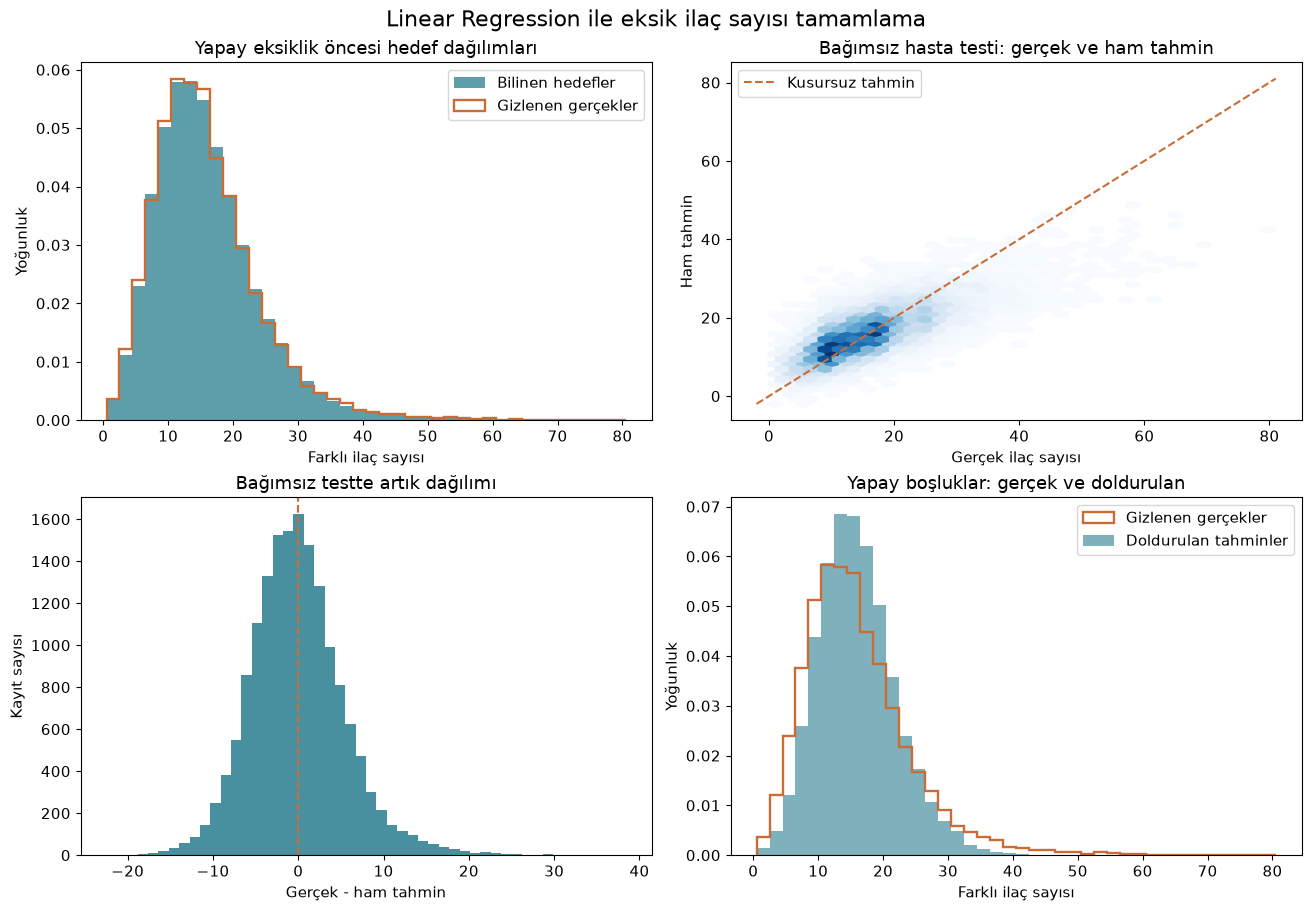

In [11]:
plt.rcParams.update({'font.family': 'DejaVu Sans', 'font.size': 11})
fig, axes = plt.subplots(2, 2, figsize=(13, 9), constrained_layout=True)
bins = np.arange(0.5, 82.5, 2)
axes[0, 0].hist(original_y.iloc[known_rows], bins=bins, density=True,
                color='#287d8e', alpha=.75, label='Bilinen hedefler')
axes[0, 0].hist(masked_truth, bins=bins, density=True, histtype='step',
                color='#cb6c37', linewidth=1.7, label='Gizlenen gerçekler')
axes[0, 0].set(title='Yapay eksiklik öncesi hedef dağılımları', xlabel='Farklı ilaç sayısı', ylabel='Yoğunluk')
axes[0, 0].legend()
axes[0, 1].hexbin(test_y, test_prediction, gridsize=35, mincnt=1, cmap='Blues')
lo = min(float(test_prediction.min()), float(test_y.min()))
hi = max(float(test_prediction.max()), float(test_y.max()))
axes[0, 1].plot([lo, hi], [lo, hi], '--', color='#cb6c37', label='Kusursuz tahmin')
axes[0, 1].set(title='Bağımsız hasta testi: gerçek ve ham tahmin', xlabel='Gerçek ilaç sayısı', ylabel='Ham tahmin')
axes[0, 1].legend()
axes[1, 0].hist(test_y - test_prediction, bins=50, color='#287d8e', alpha=.85)
axes[1, 0].axvline(0, color='#cb6c37', linestyle='--')
axes[1, 0].set(title='Bağımsız testte artık dağılımı', xlabel='Gerçek - ham tahmin', ylabel='Kayıt sayısı')
axes[1, 1].hist(masked_truth, bins=bins, density=True, histtype='step',
                color='#cb6c37', linewidth=1.7, label='Gizlenen gerçekler')
axes[1, 1].hist(missing_integer, bins=bins, density=True, color='#287d8e', alpha=.6,
                label='Doldurulan tahminler')
axes[1, 1].set(title='Yapay boşluklar: gerçek ve doldurulan', xlabel='Farklı ilaç sayısı', ylabel='Yoğunluk')
axes[1, 1].legend()
fig.suptitle('Linear Regression ile eksik ilaç sayısı tamamlama', fontsize=16)
plt.show()
plt.close(fig)

## 12. Sonuç ve değerlendirmem

Aşağıdaki özeti hesapladığım metriklerden oluşturdum. Yapay eksiklikleri doldurma
sonucunu bağımsız hasta testinden ayrı yorumladım.

In [12]:
test_score = scores(test_y, test_prediction)
train_score = scores(y_visible.iloc[train_rows], train_prediction)
baseline_score = scores(test_y, np.full(len(test_rows), mean_train))
sim_score = scores(masked_truth, missing_integer)
mae_gain = 100 * (1 - test_score['MAE'] / baseline_score['MAE'])

display(Markdown(f"""
Bu çalışmada **{len(masked_rows):,} yapay eksik ilaç sayısını** Linear Regression ile doldurdum.
Bağımsız hasta testinde ham tahminlerim için **MAE {test_score['MAE']:.4f} ilaç**,
**RMSE {test_score['RMSE']:.4f}** ve **R² {test_score['R2']:.4f}** elde ettim.
MAE sonucunu, tahminlerimin gerçek ilaç sayısından ortalama yaklaşık
**{test_score['MAE']:.2f} ilaç** uzakta olması şeklinde yorumladım.

Yalnızca eğitim ortalamasını kullandığım referansta MAE **{baseline_score['MAE']:.4f}** oldu.
Doğrusal modelle bu hatada **%{mae_gain:.2f} azalma** elde ettim.
Eğitim MAE değerim **{train_score['MAE']:.4f}**, test MAE değerim
**{test_score['MAE']:.4f}** oldu. Bu farkı tek başına kesin aşırı/eksik öğrenme
tanısı olarak değerlendirmedim.

Bilinen bütün hedeflerle yeniden eğittiğim modelin yapay boşluklara yerleştirdiğim
tamsayı tahminlerinde MAE **{sim_score['MAE']:.4f}** oldu.
İşlem sonunda hedef sütunda eksik değer kalmadığını doğruladım.
"""))


Bu çalışmada **20,353 yapay eksik ilaç sayısını** Linear Regression ile doldurdum.
Bağımsız hasta testinde ham tahminlerim için **MAE 4.2260 ilaç**,
**RMSE 5.5511** ve **R² 0.5212** elde ettim.
MAE sonucunu, tahminlerimin gerçek ilaç sayısından ortalama yaklaşık
**4.23 ilaç** uzakta olması şeklinde yorumladım.

Yalnızca eğitim ortalamasını kullandığım referansta MAE **6.0958** oldu.
Doğrusal modelle bu hatada **%30.67 azalma** elde ettim.
Eğitim MAE değerim **4.1282**, test MAE değerim
**4.2260** oldu. Bu farkı tek başına kesin aşırı/eksik öğrenme
tanısı olarak değerlendirmedim.

Bilinen bütün hedeflerle yeniden eğittiğim modelin yapay boşluklara yerleştirdiğim
tamsayı tahminlerinde MAE **4.2628** oldu.
İşlem sonunda hedef sütunda eksik değer kalmadığını doğruladım.


### Çalışmamın sınırlamaları

Hedefim sürekli bir laboratuvar ölçümü değil, tamsayı sayım değişkeni. Doğal
eksiklikleri değil, rastgele oluşturduğum eksiklikleri tamamladım. Bu nedenle
sonuçlarımı gerçek hayattaki sistematik eksikliklere doğrudan genellemedim.

Grafiklerde yüksek ilaç sayılarını daha düşük tahmin etme eğilimi gördüm.
Tek bir tahminle doldurma işleminin dağılımı daraltabileceğini ve gerçek belirsizliği
yansıtmayacağını dikkate aldım. Modelimdeki ilaç durumları dahil bütün giriş
özelliklerinin doldurma sırasında mevcut olduğunu varsaydım.

Hafta 5'teki eksik veri, kodlama ve ölçeklendirme konularını ön işlemede kullandım.
Hafta 6'daki eğitim-test ayrımı, genelleme ve eğitim/test hatalarının karşılaştırılması
konularını değerlendirmeme dahil ettim. Çalışmamda düzenlileştirme veya
hiperparametre araması uygulamadım.

## 13. Doldurduğum veri setini dışa aktarma

Doldurduğum veri setini `filled`, yapay eksiklerin gerçek/tahmin karşılaştırmasını
`comparison` içinde tuttum. Notebook'un yanında kendiliğinden ek dosyalar oluşmaması
için CSV kaydını kapalı bıraktım. CSV dosyalarına ihtiyaç duyduğumda aşağıdaki
`CSV_KAYDET` değerini `True` yaparak aynı verileri dışa aktarabilirim.

In [13]:
CSV_KAYDET = False

if CSV_KAYDET:
    filled.to_csv('diabetic_data_doldurulmus.csv', index=False, encoding='utf-8')
    comparison.to_csv('ilac_sayisi_gercek_tahmin.csv', index=False, encoding='utf-8-sig')
    print('Doldurulmuş veri setini ve karşılaştırma tablosunu CSV olarak kaydettim.')
else:
    print('Doldurduğum veri seti filled, karşılaştırma tablosu comparison değişkeninde hazır.')

Doldurduğum veri seti filled, karşılaştırma tablosu comparison değişkeninde hazır.


## Kaynaklar

1. Clore, J., Cios, K., DeShazo, J. ve Strack, B. (2014). *Diabetes 130-US Hospitals for Years 1999–2008*. UCI Machine Learning Repository. [Veri seti](https://archive.ics.uci.edu/dataset/296/diabetes+130-us+hospitals+for+years+1999-2008), [DOI](https://doi.org/10.24432/C5230J). Lisans: CC BY 4.0.
2. scikit-learn: [LinearRegression](https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.LinearRegression.html), [Pipeline ve ColumnTransformer](https://scikit-learn.org/stable/modules/compose.html), [GroupShuffleSplit](https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.GroupShuffleSplit.html).